# The testing is informative; the decisions are not

**NFL Big Data Bowl 2027 — public analysis notebook**

**What is new**

- The 10 Hz Combine signal predicts performance (**+0.299 SD/SD**) but not playing time (**−0.019**).
- Next-season playing time follows current playing time (**+0.606**) and draft position (**+0.785**), not performance (**−0.011**); the within-player change is **−0.095** (p = 0.11).
- The weekly check: next-week playing time follows this-week playing time (**+0.753**); this-week performance does not (**−0.006**, p = 0.59).
- The cap repeats the pattern: star share **−0.70** (p = 0.89); rookie snap share **−28.4** (p = 0.004); homegrown **+9.2** (p = 0.001); QB spending flattens at about **14% of payroll**.
- The measurement is working; the decisions are not.

This notebook reproduces the core results from the raw competition data plus a self-contained salary panel and a week-to-week check derived from public OverTheCap and nflverse data. It uses the 10 Hz Combine tracking and the tracking-derived Next Gen Stats in `player_play`. Competition data is CC BY-NC 4.0; do not redistribute.


In [1]:

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score

KAGGLE = Path("/kaggle/input/nfl-big-data-bowl-2027")
LOCAL = Path("data/raw")
if KAGGLE.exists():
    DATA = KAGGLE
elif LOCAL.exists():
    DATA = LOCAL
else:
    import kagglehub
    root = Path(kagglehub.competition_download("nfl-big-data-bowl-2027"))
    DATA = next(root.rglob("players.csv")).parent
print("Data:", DATA)

players = pd.read_csv(DATA / "players.csv")
combine = pd.read_csv(DATA / "combine_results.csv")
games = pd.read_csv(DATA / "games.csv")
career = pd.read_csv(DATA / "player_career_successes.csv")
games["home_team_abbr"] = games["home_team_abbr"].replace({"LA": "LAR"})
games["visitor_team_abbr"] = games["visitor_team_abbr"].replace({"LA": "LAR"})
header = pd.read_csv(DATA / "player_play.csv", nrows=0).columns
usecols = [c for c in [
    "game_id","play_id","team_abbr","nfl_id","lined_up_position","possession_team",
    "player_get_off","pressure_allowed","pass_result","separation_at_pass_forward",
    "route_ran","target","cushion","down","yards_to_go","pass_length",
    "in_motion_at_ball_snap","blitzing","pass_rushers_encountered","dropback_duration",
    "coverage_assignment","receiver_alignment","team_coverage_man_zone",
    "team_coverage_type","yardline_number","expected_points",
] if c in header]
pp = pd.read_csv(DATA / "player_play.csv", usecols=usecols)
pp = pp.merge(games[["game_id","season","week","season_type"]], on="game_id", how="left")
pp = pp[(pp["season_type"] == "REG") & pp["nfl_id"].isin(players["nfl_id"])].copy()
pp["team_abbr"] = pp["team_abbr"].replace({"LA": "LAR"})
pp["nfl_position"] = pp["nfl_id"].map(players.set_index("nfl_id")["nfl_position"])
group_map = {"WR":"WR","TE":"TE","CB":"DB","SS":"DB","FS":"DB","DB":"DB",
             "T":"OL","G":"OL","C":"OL","DE":"DL","DT":"DL","NT":"DL","OLB":"DL",
             "ILB":"LB","MLB":"LB"}
pp["position_group"] = pp["nfl_position"].map(group_map).fillna("OTHER")
print(pp.shape)


Data: /home/patrick/.cache/kagglehub/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027


(249269, 31)


## Position-specific performance residuals

In [2]:

GROUPS = {"DL":{"DE","DT","NT","OLB"},"WR":{"WR"},"TE":{"TE"},"OL":{"T","G","C"},
          "DB":{"CB","SS","FS","DB"},"LB":{"ILB","MLB"}}
NUM = ["yards_to_go","pass_length","cushion","dropback_duration","pass_rushers_encountered",
       "yardline_number","expected_points"]
CAT = ["route_ran","team_coverage_man_zone","team_coverage_type","down",
       "in_motion_at_ball_snap","blitzing","coverage_assignment","receiver_alignment","season"]

def outcome(group, df):
    if group == "DL": return -df["player_get_off"].astype(float)
    if group in {"WR","TE"}: return df["separation_at_pass_forward"]
    if group == "OL": return -df["pressure_allowed"].astype(float)
    if group == "DB": return -df["pass_result"].map({"C":1.0,"I":0.0,"IN":0.0})
    return -df["player_get_off"].astype(float)

def model():
    num = Pipeline([("imp",SimpleImputer(strategy="median",add_indicator=True)),("sc",StandardScaler())])
    cat = Pipeline([("imp",SimpleImputer(strategy="most_frequent")),
                    ("oh",OneHotEncoder(handle_unknown="ignore",sparse_output=True))])
    pre = ColumnTransformer([("num",num,NUM),("cat",cat,CAT)],sparse_threshold=1.0)
    return Pipeline([("pre",pre),("ridge",Ridge(alpha=1.0))])

def residuals(group):
    d = pp[pp["nfl_id"].isin(players.loc[players["nfl_position"].isin(GROUPS[group]),"nfl_id"])].copy()
    d["y"] = outcome(group, d)
    d = d.dropna(subset=["y"])
    if len(d) < 50: return pd.DataFrame()
    X, y, g = d[NUM+CAT], d["y"].to_numpy(), d["nfl_id"].to_numpy()
    r = np.full(len(d), np.nan)
    for tr, te in GroupKFold(5).split(X, y, g):
        m = model().fit(X.iloc[tr], y[tr])
        r[te] = y[te] - m.predict(X.iloc[te])
    d["residual"] = r
    season = d.groupby(["nfl_id","season"])["residual"].agg(raw_mean="mean",n_plays="count",within_var="var").reset_index()
    season["within_var"] = season["within_var"].fillna(0)
    noise = season["within_var"] / season["n_plays"]
    tau2 = max(float(season["raw_mean"].var(ddof=0) - noise.mean()), 0.0)
    season["shrunk_mean"] = season["raw_mean"]*tau2/(tau2+noise) if tau2 > 0 else 0.0
    season["group"] = group
    return season

perf_list = []
for g in GROUPS:
    s = residuals(g)
    if len(s):
        perf_list.append(s)
perf = pd.concat(perf_list, ignore_index=True)
perf = perf.rename(columns={"raw_mean":"perf_raw","n_plays":"perf_n","within_var":"perf_var","shrunk_mean":"perf_shrunk"})
print(perf.groupby("group").size())


group
DB    161
DL    175
OL    156
TE     63
WR    149
dtype: int64


## Player-season role panel

In [3]:

pp["is_defense"] = pp["team_abbr"] != pp["possession_team"]
team = pp.groupby(["nfl_id","season","team_abbr"]).size().reset_index(name="team_snaps")
n_teams = team.groupby(["nfl_id","season"])["team_abbr"].nunique().rename("n_teams").reset_index()
primary = (team.sort_values("team_snaps").drop_duplicates(["nfl_id","season"],keep="last")
           [["nfl_id","season","team_abbr"]].rename(columns={"team_abbr":"primary_team"}))
ps = pp.groupby(["nfl_id","season"]).agg(
    snaps=("game_id","size"), games=("game_id","nunique"),
    pass_rush_plays=("player_get_off",lambda x:x.notna().sum()),
    pass_block_plays=("pressure_allowed",lambda x:x.notna().sum()),
    coverage_plays=("coverage_assignment",lambda x:x.notna().sum()),
    routes=("route_ran",lambda x:x.notna().sum())).reset_index()
ps = ps.merge(primary, on=["nfl_id","season"]).merge(n_teams, on=["nfl_id","season"])
ps["position_group"] = ps["nfl_id"].map(pp.drop_duplicates("nfl_id").set_index("nfl_id")["position_group"])
ps = ps.merge(perf[["nfl_id","season","perf_shrunk","perf_n"]], on=["nfl_id","season"], how="left")
ps["role_pg"] = ps["snaps"] / ps["games"].replace(0,np.nan)
ps["role_pass"] = ps[["pass_rush_plays","routes","pass_block_plays","coverage_plays"]].max(axis=1) / ps["games"].replace(0,np.nan)
room = ps.groupby(["season","primary_team","position_group"])["snaps"].transform("sum")
ps["role_share"] = ps["snaps"] / room.replace(0,np.nan)
for col, name in [("role_pg","role_z"),("role_pass","role_pass_z"),("role_share","role_share_z")]:
    ps[name] = ps.groupby(["position_group","season"])[col].transform(
        lambda x:(x-x.mean())/x.std(ddof=0) if x.std(ddof=0)>0 else x*0)
ps["perf_z"] = ps.groupby(["position_group","season"])["perf_shrunk"].transform(
    lambda x:(x-x.mean())/x.std(ddof=0) if x.std(ddof=0)>0 else x*0)
ps = ps.sort_values(["nfl_id","season"])
ps["next_role"] = ps.groupby("nfl_id")["role_z"].shift(-1)
ps["next2_role"] = ps.groupby("nfl_id")["role_z"].shift(-2)
ps["next_season"] = ps.groupby("nfl_id")["season"].shift(-1)
ps["next2_season"] = ps.groupby("nfl_id")["season"].shift(-2)
ps = ps.merge(players[["nfl_id","display_name","draft_year","draft_overall_pick"]], on="nfl_id", how="left")
ps = ps.merge(combine[["nfl_id","ngs_final_score","ngs_college_production_score","ngs_athleticism_score"]], on="nfl_id", how="left")
# Draft-capital percentile on unique players, not player-seasons.
pu = players.merge(combine[["nfl_id","ngs_final_score","ngs_college_production_score","ngs_athleticism_score"]], on="nfl_id", how="left")
pu["position_group"] = pu["nfl_position"].map(group_map).fillna("OTHER")
pu["B_draft"] = 0.0
for (yr, pos), idx in pu.groupby(["draft_year","position_group"]).groups.items():
    sub = pu.loc[idx]; picks = sub["draft_overall_pick"]; r = picks.rank(method="average", ascending=False)
    pu.loc[idx,"B_draft"] = (r-1)/max(len(sub)-1,1)
    pu.loc[sub.index[picks.isna()],"B_draft"] = 0.0
pu["B_draft"] = pu["B_draft"].clip(0,1)
ps = ps.merge(pu[["nfl_id","B_draft"]], on="nfl_id", how="left")
for col in ["ngs_final_score","ngs_college_production_score"]:
    ps[col+"_z"] = (ps[col]-ps[col].mean())/ps[col].std(ddof=0)
ps["prestige_nodraft"] = ps[["ngs_final_score_z","ngs_college_production_score_z"]].mean(axis=1)
ps = ps.merge(career[["nfl_id","career_offensive_snaps","career_defensive_snaps",
                      "career_special_teams_snaps","career_games_active","career_games_started"]], on="nfl_id", how="left")
ps["career_snaps"] = ps[["career_offensive_snaps","career_defensive_snaps","career_special_teams_snaps"]].sum(axis=1)
ps["season_c"] = ps["season"].astype(str)
print(ps.shape)


(722, 41)


## Role persistence and within-player validation

In [4]:

t1 = ps[(ps["next_season"] == ps["season"]+1) & ps["next_role"].notna()].copy()
t2 = ps[(ps["next2_season"] == ps["season"]+2) & ps["next2_role"].notna()].copy()
fe = " + C(position_group) + C(season_c)"
base = t1[t1["position_group"] != "DB"].dropna(
    subset=["role_z","perf_z","B_draft","prestige_nodraft","season_c","position_group","primary_team"]).copy()
t2 = t2[t2["position_group"] != "DB"].dropna(
    subset=["role_z","perf_z","B_draft","season_c","position_group"]).copy()

def fit(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups":data["nfl_id"]})

concurrent = fit(f"role_z ~ perf_z + B_draft + prestige_nodraft{fe}", base)
base["role_gap"] = concurrent.resid
next1 = fit(f"next_role ~ role_z + perf_z + B_draft{fe}", base)
next1p = fit(f"next_role ~ perf_z + B_draft + prestige_nodraft{fe}", base)
next2 = fit(f"next2_role ~ role_z + perf_z + B_draft{fe}", t2)
base["team_role_mean"] = base.groupby(["primary_team","season"])["role_z"].transform("mean")
base = base.dropna(subset=["team_role_mean"]).copy()
next1_team = fit(f"next_role ~ role_z + perf_z + B_draft + team_role_mean{fe}", base)
sens = {}
for role_col, label in [("role_pass_z","pass-play role"),("role_share_z","cohort role share")]:
    sub = t1[t1["position_group"] != "DB"].dropna(
        subset=[role_col,"perf_z","B_draft","next_role","season_c","position_group"]
    )
    sens[label] = fit(f"next_role ~ {role_col} + perf_z + B_draft{fe}", sub)
dd = ps[ps["position_group"] != "DB"].sort_values(["nfl_id","season"]).copy()
dd["d_role"] = dd.groupby("nfl_id")["role_z"].diff()
dd["d_perf"] = dd.groupby("nfl_id")["perf_z"].diff()
dd["d_next"] = dd.groupby("nfl_id")["season"].diff()
diff = dd[dd["d_next"] == 1].dropna(subset=["d_role","d_perf"])
diff_fit = fit("d_role ~ d_perf", diff)

def show(fit, label, terms):
    print(label)
    for term in terms:
        if term not in fit.params: continue
        ci = fit.conf_int().loc[term]
        print(f"  {term}: {fit.params[term]:+.3f} ({ci[0]:+.3f}, {ci[1]:+.3f}) p={fit.pvalues[term]:.3g}")

show(concurrent, "Concurrent role", ["perf_z","B_draft","prestige_nodraft"])
show(next1, "Next role", ["role_z","perf_z","B_draft"])
show(next1p, "Next role (performance only)", ["perf_z","B_draft","prestige_nodraft"])
show(next2, "Role at t+2", ["role_z","perf_z","B_draft"])
show(next1_team, "Next role (team control)", ["role_z","perf_z","B_draft","team_role_mean"])
show(diff_fit, "Within-player change", ["d_perf"])

# Position replication and role-measure sensitivity tables for figures.
pos_rows = []
for g, sub in t1.groupby("position_group"):
    if len(sub) < 25:
        continue
    if g == "DB":
        sub = sub.dropna(subset=["role_z","B_draft","next_role"])
        f = fit("next_role ~ role_z + B_draft", sub)
        pos_rows.append({"position":g,
                         "role":f.params["role_z"],"role_lo":f.conf_int().loc["role_z",0],"role_hi":f.conf_int().loc["role_z",1],
                         "perf":np.nan,"perf_lo":np.nan,"perf_hi":np.nan,
                         "draft":f.params["B_draft"],"draft_lo":f.conf_int().loc["B_draft",0],"draft_hi":f.conf_int().loc["B_draft",1]})
    else:
        sub = sub.dropna(subset=["role_z","perf_z","B_draft","next_role"])
        f = fit("next_role ~ role_z + perf_z + B_draft", sub)
        pos_rows.append({"position":g,
                         "role":f.params["role_z"],"role_lo":f.conf_int().loc["role_z",0],"role_hi":f.conf_int().loc["role_z",1],
                         "perf":f.params["perf_z"],"perf_lo":f.conf_int().loc["perf_z",0],"perf_hi":f.conf_int().loc["perf_z",1],
                         "draft":f.params["B_draft"],"draft_lo":f.conf_int().loc["B_draft",0],"draft_hi":f.conf_int().loc["B_draft",1]})
pos_df = pd.DataFrame(pos_rows)
sens_rows = []
for label, fit_obj, role_term in [
    ("Raw snaps", next1, "role_z"),
    ("Pass-play role", sens["pass-play role"], "role_pass_z"),
    ("Cohort role share", sens["cohort role share"], "role_share_z"),
    ("Team control", next1_team, "role_z"),
]:
    for key, term in [("role", role_term), ("performance", "perf_z"), ("draft", "B_draft")]:
        if term not in fit_obj.params:
            continue
        ci = fit_obj.conf_int().loc[term]
        sens_rows.append({"model": label, "series": key, "coef": fit_obj.params[term],
                          "lo": ci[0], "hi": ci[1]})
sens_df = pd.DataFrame(sens_rows)

# OOF role prediction.
X = base[["role_z","perf_z","B_draft","position_group","season_c"]]
y = base["next_role"]; groups = base["nfl_id"].to_numpy()
oof = np.full(len(base), np.nan); oof_perf = []
for tr, te in GroupKFold(5).split(X, y, groups):
    f = smf.ols("next_role ~ role_z + perf_z + B_draft + C(position_group) + C(season_c)",
                data=base.iloc[tr]).fit()
    oof[te] = f.predict(base.iloc[te]); oof_perf.append(float(f.params["perf_z"]))
print("OOF R2", round(r2_score(y, oof),3), "perf coef range", round(min(oof_perf),3), round(max(oof_perf),3))

# Descriptive tails on reliable samples.
tail = base[base["perf_n"] >= 50].copy()
tail["allocation"] = "mid"
tail.loc[(tail["perf_z"] >= tail["perf_z"].quantile(.75)) & (tail["role_gap"] <= tail["role_gap"].quantile(.25)),
         "allocation"] = "low role / high performance"
tail.loc[(tail["perf_z"] <= tail["perf_z"].quantile(.25)) & (tail["role_gap"] >= tail["role_gap"].quantile(.75)),
         "allocation"] = "high role / low performance"
print(tail.groupby("allocation")[["role_z","perf_z","role_gap","next_role"]].agg(["count","mean"]).round(3))


Concurrent role
  perf_z: -0.129 (-0.246, -0.012) p=0.0309
  B_draft: +1.458 (+0.811, +2.105) p=1.01e-05
  prestige_nodraft: +0.286 (+0.141, +0.431) p=0.000112
Next role
  role_z: +0.624 (+0.527, +0.722) p=4.25e-36
  perf_z: +0.009 (-0.101, +0.119) p=0.871
  B_draft: +0.778 (+0.328, +1.228) p=0.000698
Next role (performance only)
  perf_z: -0.076 (-0.209, +0.057) p=0.262
  B_draft: +1.538 (+0.767, +2.309) p=9.24e-05
  prestige_nodraft: +0.229 (+0.056, +0.402) p=0.0096
Role at t+2
  role_z: +0.435 (+0.205, +0.664) p=0.000205
  perf_z: -0.151 (-0.379, +0.077) p=0.194
  B_draft: +1.273 (+0.373, +2.173) p=0.00555
Next role (team control)
  role_z: +0.682 (+0.565, +0.799) p=3.18e-30
  perf_z: +0.004 (-0.105, +0.114) p=0.938
  B_draft: +0.749 (+0.299, +1.199) p=0.0011
  team_role_mean: -0.196 (-0.418, +0.027) p=0.0851
Within-player change
  d_perf: -0.096 (-0.212, +0.019) p=0.101
OOF R2 0.502 perf coef range -0.024 0.056


                            role_z        perf_z        role_gap         \
                             count   mean  count   mean    count   mean   
allocation                                                                
high role / low performance      9  1.289      9 -1.200        9  1.024   
low role / high performance     13 -0.543     13  1.401       13 -0.635   
mid                            173  0.403    173  0.031      173  0.165   

                            next_role         
                                count   mean  
allocation                                    
high role / low performance         9  0.826  
low role / high performance        13 -0.453  
mid                               173  0.475  


## 10 Hz Combine movement linkage

In [5]:

# Generic 10 Hz Combine movement composite and its linkage.
ct = pd.read_csv(DATA/"combine_tracking.csv", usecols=["event_id","nfl_id","entity_type","time","x","y","s","a","drill_name","attempt"])
ct = ct[(ct.entity_type=="PLAYER") & ct.nfl_id.notna()].copy()
ct["time"] = pd.to_datetime(ct["time"])
ct = ct.sort_values(["event_id","nfl_id","attempt","time"])
g = ct.groupby(["event_id","nfl_id","attempt"])
ct["elapsed"] = (ct["time"]-g["time"].transform("first")).dt.total_seconds()
ct["from_start"] = np.hypot(ct["x"]-g["x"].transform("first"), ct["y"]-g["y"].transform("first"))
def attempt_stats(d):
    d=d.sort_values("time"); e=d["elapsed"].to_numpy(); s=d["s"].to_numpy(); a=d["a"].to_numpy()
    x=d["x"].to_numpy(); y=d["y"].to_numpy(); dist=np.hypot(x-x[0],y-y[0]); path=np.sum(np.hypot(np.diff(x),np.diff(y)))
    hit=np.where(dist>=1)[0]; first=e<=0.5
    return pd.Series({"max_speed":s.max(),"max_accel_first":a[first].max() if first.any() else np.nan,
                      "time_to_1yd":e[hit[0]] if len(hit) else np.nan,
                      "path_eff":dist[-1]/path if path>0 else np.nan})
att = g.apply(attempt_stats, include_groups=False).reset_index()
att = att.merge(ct[["event_id","nfl_id","attempt","drill_name"]].drop_duplicates(), on=["event_id","nfl_id","attempt"], how="left")
for col in ["max_speed","max_accel_first","time_to_1yd","path_eff"]:
    att[col]=att.groupby("drill_name")[col].transform(lambda x:(x-x.mean())/x.std(ddof=0) if x.std(ddof=0)>0 else x*0)
cm = att.groupby("nfl_id").agg(speed=("max_speed","mean"),accel=("max_accel_first","mean"),
                               time1=("time_to_1yd","mean"),path=("path_eff","mean")).reset_index()
z = cm[["speed","accel","path"]].apply(lambda x:(x-x.mean())/x.std(ddof=0))
cm["combine_movement"] = pd.concat([z, -cm["time1"]], axis=1).mean(axis=1)
print("Combine movement players:", len(cm))

perf_sample = ps.merge(cm, on="nfl_id", how="left").dropna(subset=["combine_movement","perf_z"])
perf_sample = perf_sample[perf_sample["position_group"] != "DB"].copy()
role_sample = base.merge(cm, on="nfl_id", how="left").dropna(subset=["combine_movement"])
combine_rows = []
for data, formula, label in [
    (perf_sample,"perf_z ~ combine_movement + B_draft + C(position_group) + C(season_c)","performance"),
    (role_sample,"role_z ~ combine_movement + B_draft + C(position_group) + C(season_c)","role"),
    (role_sample,"role_gap ~ combine_movement + role_z + B_draft + C(position_group)","role gap"),
]:
    f=smf.ols(formula,data=data).fit(cov_type="cluster",cov_kwds={"groups":data["nfl_id"]})
    ci=f.conf_int().loc["combine_movement"]
    combine_rows.append({"outcome":label,"coef":f.params["combine_movement"],"ci_low":ci[0],"ci_high":ci[1],"p":f.pvalues["combine_movement"],"n":len(data)})
    print(label, f"{f.params['combine_movement']:+.3f}", f"({ci[0]:+.3f}, {ci[1]:+.3f})", "p", f"{f.pvalues['combine_movement']:.3g}", "n", len(data))
combine_df = pd.DataFrame(combine_rows)


Combine movement players: 510
performance +0.429 (+0.245, +0.612) p 4.58e-06 n 543
role -0.152 (-0.386, +0.082) p 0.202 n 237
role gap +0.034 (-0.030, +0.098) p 0.297 n 237


## Figures

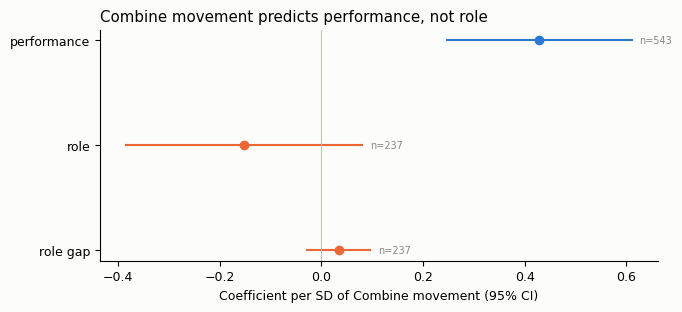

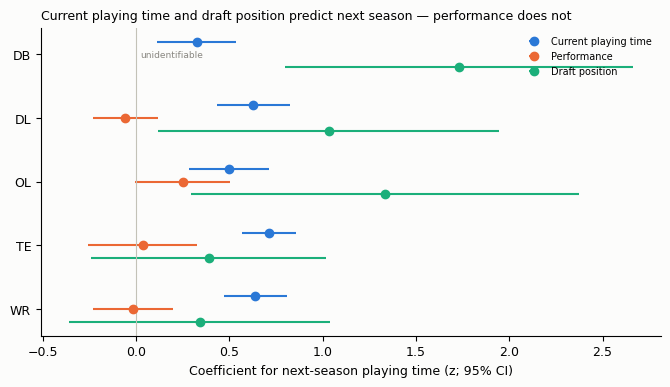

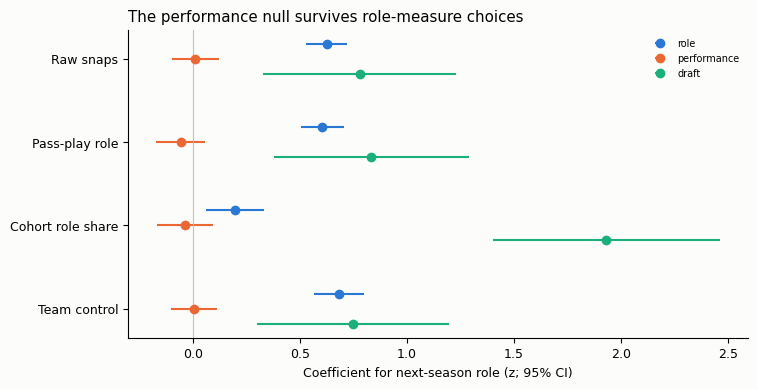

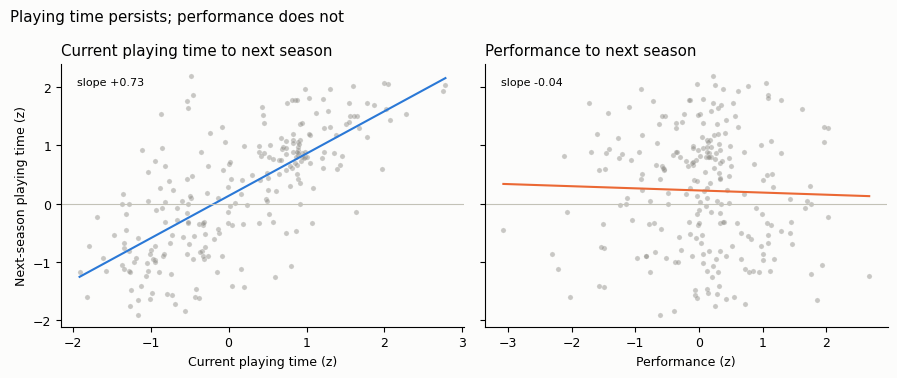

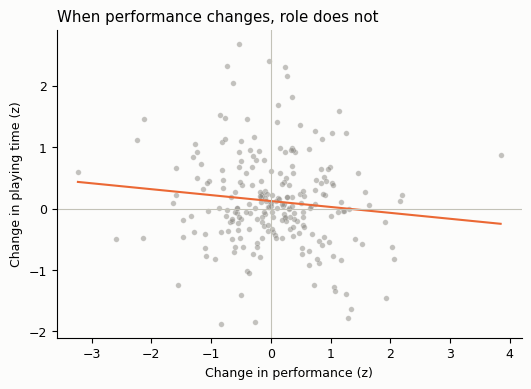

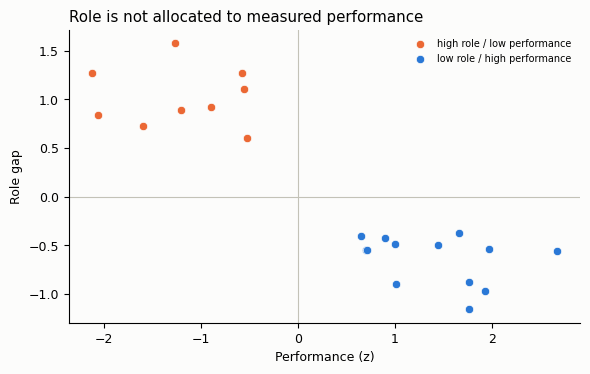

In [6]:

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GRAY, BASELINE, SURFACE, INK = "#2a78d6","#eb6834","#1baf7a","#898781","#c3c2b7","#fcfcfb","#0b0b0b"
plt.rcParams.update({"figure.facecolor":SURFACE,"axes.facecolor":SURFACE,"font.size":9,
                     "axes.spines.top":False,"axes.spines.right":False,"grid.color":"#e1e0d9"})

# Combine linkage.
fig, ax = plt.subplots(figsize=(7.2, 3.0))
cf = combine_df.iloc[::-1].reset_index(drop=True)
for i, row in cf.iterrows():
    color = BLUE if row["ci_low"] > 0 else ORANGE
    ax.errorbar(row["coef"], i, xerr=[[row["coef"]-row["ci_low"]],[row["ci_high"]-row["coef"]]],
                fmt="o", color=color, ecolor=color, capsize=0, markersize=6)
    ax.annotate(f"n={int(row['n'])}", (row["ci_high"], i), xytext=(5,0), textcoords="offset points",
                va="center", fontsize=7, color=GRAY)
ax.axvline(0, color=BASELINE, lw=.8); ax.set_yticks(range(len(cf))); ax.set_yticklabels(cf["outcome"])
ax.set_xlabel("Coefficient per SD of Combine movement (95% CI)")
ax.set_title("Combine movement predicts performance, not role", loc="left")
fig.savefig(FIG/"combine_linkage.png",dpi=180,bbox_inches="tight"); plt.show()

# Next-role forest.
fig, ax = plt.subplots(figsize=(8, 4))
yy = np.arange(len(pos_df))
for key, label, color, off in [("role","Current playing time",BLUE,-.2),("perf","Performance",ORANGE,0),("draft","Draft position",AQUA,.2)]:
    coef = pos_df[key].to_numpy(); lo = pos_df[key+"_lo"].to_numpy(); hi = pos_df[key+"_hi"].to_numpy()
    mask = ~np.isnan(coef)
    ax.errorbar(coef[mask], (yy+off)[mask], xerr=[(coef-lo)[mask],(hi-coef)[mask]],
                fmt="o", color=color, ecolor=color, capsize=0, markersize=6, label=label)
    if key == "perf":
        for idx in np.where(~mask)[0]:
            ax.text(0.02, yy[idx]+off, "unidentifiable", fontsize=6.5, color=GRAY, va="center")
ax.axvline(0, color=BASELINE, lw=.8); ax.set_yticks(yy); ax.set_yticklabels(pos_df["position"]); ax.invert_yaxis()
ax.set_xlabel("Coefficient for next-season playing time (z; 95% CI)"); ax.legend(frameon=False, fontsize=7)
ax.set_title("Current playing time and draft position predict next season — performance does not", loc="left", fontsize=9)
fig.savefig(FIG/"next_role_forest.png",dpi=180,bbox_inches="tight"); plt.show()

# Role-measure sensitivity.
fig, ax = plt.subplots(figsize=(8, 4))
models = list(dict.fromkeys(sens_df["model"]))
ypos = {m:i for i,m in enumerate(models)}
for series, color, off in [("role",BLUE,-.18),("performance",ORANGE,0),("draft",AQUA,.18)]:
    sub = sens_df[sens_df["series"] == series]
    ax.errorbar(sub["coef"], [ypos[m]+off for m in sub["model"]],
                xerr=[sub["coef"]-sub["lo"], sub["hi"]-sub["coef"]],
                fmt="o", color=color, ecolor=color, capsize=0, markersize=6, label=series)
ax.axvline(0, color=BASELINE, lw=.8); ax.set_yticks(range(len(models))); ax.set_yticklabels(models); ax.invert_yaxis()
ax.set_xlabel("Coefficient for next-season role (z; 95% CI)"); ax.legend(frameon=False, fontsize=7)
ax.set_title("The performance null survives role-measure choices", loc="left")
fig.savefig(FIG/"role_sensitivity.png",dpi=180,bbox_inches="tight"); plt.show()

# Role persistence vs performance.
fig, axes = plt.subplots(1,2,figsize=(9,3.8),sharey=True)
for ax,col,label,color in [(axes[0],"role_z","Current playing time (z)",BLUE),(axes[1],"perf_z","Performance (z)",ORANGE)]:
    ax.scatter(base[col],base["next_role"],s=14,c=GRAY,alpha=.45,edgecolors=SURFACE,linewidths=.3)
    coef=np.polyfit(base[col],base["next_role"],1); xs=np.linspace(base[col].min(),base[col].max(),50)
    ax.plot(xs,np.polyval(coef,xs),color=color,lw=1.5); ax.axhline(0,color=BASELINE,lw=.8)
    ax.set_xlabel(label); ax.set_title(label.split(" (")[0]+" to next season",loc="left")
    ax.annotate(f"slope {coef[0]:+.2f}",(0.04,.92),xycoords="axes fraction",fontsize=8)
axes[0].set_ylabel("Next-season playing time (z)")
fig.suptitle("Playing time persists; performance does not",x=.01,ha="left")
fig.tight_layout(); fig.savefig(FIG/"role_persistence.png",dpi=180,bbox_inches="tight"); plt.show()

# Within-player change.
fig,ax=plt.subplots(figsize=(6,4))
ax.scatter(diff["d_perf"],diff["d_role"],s=16,c=GRAY,alpha=.5,edgecolors=SURFACE,linewidths=.3)
coef=np.polyfit(diff["d_perf"],diff["d_role"],1); xs=np.linspace(diff["d_perf"].min(),diff["d_perf"].max(),50)
ax.plot(xs,np.polyval(coef,xs),color=ORANGE,lw=1.5); ax.axhline(0,color=BASELINE,lw=.8); ax.axvline(0,color=BASELINE,lw=.8)
ax.set_xlabel("Change in performance (z)"); ax.set_ylabel("Change in playing time (z)")
ax.set_title("When performance changes, role does not",loc="left")
fig.savefig(FIG/"within_player_change.png",dpi=180,bbox_inches="tight"); plt.show()

# Role gap tails.
tail_plot=tail[tail["allocation"]!="mid"]
fig,ax=plt.subplots(figsize=(6.6,3.8))
for label,color in [("high role / low performance",ORANGE),("low role / high performance",BLUE)]:
    sub=tail_plot[tail_plot["allocation"]==label]
    ax.scatter(sub["perf_z"],sub["role_gap"],s=36,c=color,edgecolors=SURFACE,linewidths=.5,label=label)
ax.axhline(0,color=BASELINE,lw=.8); ax.axvline(0,color=BASELINE,lw=.8)
ax.set_xlabel("Performance (z)"); ax.set_ylabel("Role gap"); ax.legend(frameon=False,fontsize=7)
ax.set_title("Role is not allocated to measured performance",loc="left")
fig.savefig(FIG/"role_gap_tails.png",dpi=180,bbox_inches="tight"); plt.show()


## Dollar layer: cost efficiency and the rent proxy

The salary panel merges OverTheCap positional cap spending (2023–2025), nflverse snaps/rosters/stats/schedules, and the 2025 archived OTC team cap ledger. The panel is embedded below as a compressed CSV so this notebook is self-contained. The derivation and source notes are in the repository (`src/salary/`, `docs/EXTERNAL_DATA.md`, `docs/SOCCER_DATA.md`). All models are observational; the rent residual is a cap-allocation residual, not a causal rent.


In [7]:

import base64, zlib, io
SALARY_B64 = "eJxtnNvSZMdxne/9LD0du85Vl+BBEmQackgUbV0hYBkUGSYJGKBDobf392Xu/qcnbGHEmenpv7uyKg8rV67aP3//3c8//OXx1++/+/Pj579+99O3P//hu5++f/z0ww//64/ff/vzX7778X7lDz/8+ft/++mHf//L+4v/8cP/+esf3l/43//j/sO/8tIXf3n78H//419+fvz4wx//8tdv/+cff//7xw+///233//43bc/fv/Ttz/+6bv/iDfE38p1/fntnZ9fe/+ReOFPP/zbtz9+9x8//fCnPz1+Dpu+/df/VK/aHr/69W8f17OP0+s5q8wxzuiTl0pdpY9dRu11X3XxEv9Udr9q7b21cw1eavXqo+41+Lle+vEHT7t2X9feq/XT++PxKPV5Pebkf67nNfjUfdo4c5y962M+Wy/7Yp197uE3tf7c6/AFo4411xyPVp+8g8+8rt1WWeVRDp+0e+2u95RTH5qTNv3iq99oU5ksdtUz+b9ztt89Jzb1ep0x2llVm8bmb/tqs9dSa66fZUw+qcxeRpjU6i7XOGu1UucamtSwpl4tbZp9jbn4K0ZtLFrlOme0tua162S1V3+u0/n51vfmk+qjjedZF1/CNq06GlZq0y7sya79YPh5s+mXv/m1q+0sie0dta1WZ5zTNdvpfDlH44FpOauII2Bb5r48On6vLG21Uc/VSvcHS2mL9+3GB2wWiVEFc9j96/FJB9irH76FPdyl78d4LhZfW2VX+e9g1nquea5zXWWyNVd5fFrnueeZu/hDHF0Pq6ZbzBexd+fMN7P+8y9jvWNjF1/YrqsN/erCQ+bqhe0ra5fCS5P342r+ttmwE1ZxZBUP5aTOGmHVwRtqw2d55czzsmqtPKmyW+M418WW816MGrjI2kZA51/x/caC+eJ+cADOox6O73m1q87W+yiDj9coHHb2yTlwpl/Y9Ktff6NRuDO+x7+1gyeGl7S5Od+rb5wvzOyrT5yXPWQ7+SoN2G3zg+3CpTpmhPvxF0xmb9iRiUnbIxozD+ribdMYWL3hF4/O0RU+srqXHt3jU93PTexy8LV7PIeX2pOAmov98NP77X74/j6Tn2Kp7+73ddjUJx6LyaPxk3WE+4WLsGT+f8WpcMRhjSd1evOciCk2l4gmjNh+N+NsUg6eRMYpq3lOR3PKvo3iBCYuRbR2AmRgVbvOXDg16YJd2OPxaT8nnzxISbh3xZ3ZlGccERG8cc1dw6wy1tXxno2brfZm1t9/9d8j+7ErOMXUaa5IYnyVQdQWH8JLehY5ATfvnZx2THlhV2GJHO+4Bn+MH5wXuZGfWewkSeW263VUvLQHn1Nx4lImVnXdESfGB9lR0tiThFaLPsJR6Dmf6nHnB5tBeJAGd9hUT+VLLnef+Hhzv8h+A2tId4aL25wxNQ3exQJ7D1+bOAi5BDN6Y2MinZgLsKfv0VlrZD+TCTmzLLwW13wldMInYwprWRSONAY5pmjssEKQd4tpdTzOIqNvI9Nt7WR9nXfwxX5Nw+NWhhTngFUcU73ebfrN7zJVj0lA1cZG9Agp0+zBH9mcWSJL9ErWaHhfGaaJWD+pET+kQvFz1KQoQuTy1dnwTeVq7Q6pcme+i302C7Nh+NchSVy40DhsDvt9LjdqagpOTDgczr49Ps1GJdssHI8kkV2kPsKO2miaLdQ6is+bTd/8g8vlSzqJhI8epOESx1SIlL1x4U4ZioRO9FOdpqsoO9L+RfGgunCiFM8SUUZMsA63t7vV43a9NW7fY+FErYWCOopn9icl+7hPnAlZ4Dx6If0YBngJMWaJ/0SO31bYeQ12jMOJPIGV1KDWsY2K8GbVV7/9TcACfKKRHYkeEsWKcsOX6G0s0ygK48fhqLZr8l8j+5H1cYiC61oaH5HeyNZdaGK50qwV6a/edhHl7Pe2srPr5dEsv1igs5KD+UJCaD3HFLyQcYE5nFrkTzMtvwAunFpiCmytninF8no37Bf//DcaxsrWwUkJbn4qw4o0Ry0mPPkVmKKRpXA+MjbJKIywOLN+bCJVELRxguQMNpWMyBJHe1Wq0q8IK+rhKYYwBQv3HnghaGdQKNkPAEzZQqo1qbTDCN18xWNaqYAipAQSEAufEVcEB2maqoDfv/vg3/3DP2uU/mvWH+uEH/DlnTRACSeXx+++i8Br4LF5/27+64I2MuKJ38dd5Pg81kh6oj5qlfbU/vJCCsAihA8Vl8jEKmBGxVEqyIqDNGN3D5XUR8AQzNQk3JC8WIehXQxL0qfRRSKeJg/cgtK03iz7L19/Fce1rTGguDauhBFXtwSRaSkXuFaLnIFXcELke2rOCqcjn1E8qCo4OUUyw6taRSigbkH9OK9r3Gmwi2KX0MWyjmXkV2psv9xEDuUxcM0jjmC7urvwGMWM61+AttTijK5NCcDIbfi8++BvvvpluFfh8wdFk1OrK8KGYN1imrUjc1qECRk2jNDSwaNaLc6Gvx8Oj5ONzRjWblcg2hYCji9CC68ekQUr1QnHqM+oDeZpK+ZVI7KWWR7AwVcTPo9PjYOhVGzL/XTPwig86oh1BPHvPvjbgEvEwQKvGy58XJm3D2IQLQhuCZgLUGVN3NRKWhJqdGaMofdVDhWUMcItcTzgNhCYWNieVNTf+TKLxoESTBfCIsk3ZgwzyBZdgQLButrAsWMDLtnIROSLNsUA1McGSuTXivyOV7K/M+rOO2L65l/+NhAT/ivyNdELBzwrkw2/cI42r4AWUxP70q/wwGiscAeKFkCgz7kyJCmWfAjVsQINx8sqXr/LVkALqhEHb/HVLAAhYPdwfCwRRPdpc1xmTAyh5yH0+AACdNuziZjsGGYaRjql+SqBZr4oXP/y9xFa9kLgTn7CDiYzWtQFfcGDyiaM5osMgaVgnwDtvM2EfsXmJ+i4DJ5hwsPN+nml+L3SMs5g2kmBivH9ODBXihtb6AubQaHqNlST+khGpRjQYn2iqBIIlC73iwCv69U3mqKPofAO3L+xxQIJbepUhKRoWkgkOCOjk7ps/jxVXN1ugfgiXc9sWLDhiEPFGr7CpoO9wCDgVT4ToyIHcvb3eS3r/IhWh76X4BK3G9N8DOWTFPtpmuNIlnR43byCGx56TveyDByqiinCpk5MTPNds96+Ife/+9rTIklSDe0obLFj0/EJNsJzEZ9Eg09rT4/ImXEIM46mmv6WYFpkENiJrwacVpLAIpV9HFY5r3YEgMl7cBDOlEb3SayQ7clZfLFNIO+NyNARSWADh7VEg/BJ1LRHNC/LAuMnUrfsU6u2vJ/V19/8SrP4CRA433f41ploT2hE6dCRT9Rjci+Lpdyyb3NlQ0Kcg3mwaMwThhL5fHkJpEFoto+G5GUWSZ2AJR43B03dGE9CkUPBkN5wpGMkPVvQG7hK1K8dZunaehPZTDBi3eJtINBxQAPzC/z0T7+2bnWWT8xgA9scaAHwfXWdNpwpDhA4uC32YB4bkcgtZE+jCqjHt82sZIt/prJOwSHF7bar7bshpm0fsi9sMegYHyWhAt8IbeuvPX2VeMCv8AiyHHl/YvyxZ6IUmkiAJ3FYwAIbNBYIYnl3wv/21T+FE0YeB5dRjckqCZ7IbmAaEt3V4wCBQoTMEVMR19FjEiiLjT5ubQ+SBtxECOCWxWwXJFMG134dFyi9C2UpeCydzEzxwB5qAmWzimM5LvMIqwdUEfCe1iA9shwJDZYaCYPTqlvuRvZnfNE+/teILXIBlVdeilRbkwPTJWXJtsguWhVSNwCQXMx+4WORVzgOgtCumhM6SY4JXIt8gHn7hTFuhIEji6ZJEMMqHkQTgMwGtBwbaoKNcBZXb9sCTrt3MmC0WJ7pzqJ1IjiXq9lftPlf/WMYRKyyDLBPdDw3KQaakM3oxGvJw6w2KfR1ZN3IeAIMvmPbTwsZotiRkIkYqqqAeX2cU311JdQcToR6anEDrtYn9oVZplsZAOrAJAtaaI7lsa84J9rPWNCwwuIn2AWAIg/aP0ZKeQdO/xh2CV7YRPmfnmElQJx6VzT6WjEDNlE2ugk2oB/1x6zZrNm4XPgkbaNMHZ4OSqrrA+fePFOnWIFGLI+bMk6KrKJA+nHSuNSSAUM4TzdLF8Y9pN5AW5v3UencgEgWS4aD+oj/WVbf/e/r30YlZvHTZHpJ2iZ5S7ZcNg9H91tRszh8glYIQeIILyUOj/iF/E/Ihf/JIuFbOh/Y4WWVKSCPC0A05ToofMAjmxJeEncQGVI+LZI7CM6sw4Gz1xdxBUY5UgEGiXVyJ91EDmRH5K3snN7R+zdZjmyfgx7DxRLoNmEnLodTjQgj8h15yYaBhr/HeVEDcB6aLxARhkSwsWDCTaAsabI+qtaLbyImyX/4Ie8hjOWb2JwuK0TdpU+O9F5tP6qwiBOzsSwzXLiJzrAW1BHYKTgIAFeRpHlP738TKJZegvyFQ8d3RmgLmpbJnEVGLgAkiddZLKatQFMy1OATki6NNDAwToxsOcTztJstUOFNziQ1DUqoVnPOjeCoOqKBLetYE5XxftzuoogFC4pXB11NzmPnQE32hWkVUUVDYCtjX/EO4X+hVax/kd44NLuOJGPBLSRAzs+gNG4oD5RKqgaVhaXHCqnSgzpGKI90X3zsCKaaJDwV565Ztb3OioLagsnYAhbyILm2AG26nOLQJl6acs5AUzOhhZjiTKusqywZpJYpg06LRqAKsr8Ag3+rTRLOdnDNuBhBeNZggGQB/fbAF7g65y0tKUCoPVpqvWZa3UUIJ3GTJXiZMDD0tqndE4QhkykZvOxnp9C+nZhu8DJfDwAHHwI0RJ1AV7ZZonrK+QwpfbrcE6dEi1UDHErAvAPByIGCt216Pex2zRxNmSVeAlrMyIpdQCOdTDdLSxTxs64sn7KXoJIsVmJ90CoBQwhiUc2Q+gC4pBFaa6EbfcmD8HGV1ESHQ91xC8mCRouoNedKNRRfK/3pvtH8TemgZNJIVJwA5UjQ99n7+p3cCReOlTQGIo9UUeWE8DHnPfuEX9EocpjS8LxYwy7e1SRR8VCnLj1eojxI85DROJWPHBhI8BJ8g5XsTC2IAqaJX4Fw8VXqM1jkk6fgl2+8nNwswAMl0PI0m/TOx17Jy7CuLqGNP0cHwD+mTTEX8VR2lMUlHIumgsaaQsKHkixWtCc6NF4V4wIrjhaIzc7SM6jhmetXDE96vi1HWJbgcRvFqRJ115HAGCyYXtcdpg4Ne1WQPxV7CuGdAUjjYdR2ieTyYWuqB2ATocx3yyG7ijeTErHTwdtii5O0IkcI1NZu+xTwO2qwdREYTzMlashTIZ93Ewfv38EfkjQre07NY0d7MIM5GHkVKzsbpyl00tGpNHAs2Eb6BIS2jYpPhpX+KLsbyLoHZqeWOtMbgYV3MO60QiQTdgj3aOPNsns4cuxSAN0yx0kEcgA2QVsy3HFq8DLSkCY8MMBOfvoUOTyytGzyXb9H1Lwi7f8ZtL8wO2WTfwYcL01swXhKJuCu0tTLo/Uv5iQOxyN69OZ3E3QkNELtaBGHy3faREj/rzeTksaVLiUvAGYcj2TzdzkbcpSziBONBFdsz08mswSdUYRXQXUSvvuuyM4eyUgcU3pfnFS7Jwh09ayK0HSOFT1jN9y7e0LGKhJNJAU30jjH9CZc14PJskswwj/1ZDsNY3K69P/1hVH3ZIRd7VEIph1wrs6GH0RrS1ZHoopt6OKCW9IvUyDeMWZwbU72dMohk865V86wf1DT5QNV0JPvHrPNaduhYULbawa8b1dCWelZ0CyJwUZRLmPhgBR0qwKteQm0WOzABKXLydj7YSVqZ7fE0fIN5y6t3WkbubnZZgRbTTad0rY1pj5Z0SRQyH4YTnteMysWeV28hW9fMRvWolryuHiXNYnfRUiyMYSJODzqClCJwgRWkVHShdkda9UwG0/jR7QfJ+UgzMSxZVPejyrH3Y6wt5WI2jwypChCc4l52FheWdGJ6NKAJZH/yHaF/SXvXZLrOw+UQLgMcyGPLoBJASfKWq9qdWZwVz1QH0FkvdBDiCDRNdX00ybldZmvHhMdoS3p6BkdjiQpbpt0Z1EzUJ2wEpL9zbKk3OWUQVqyliCX7CjAwfRIHK2Tjx0DEoqrtdpQsoplcaLBduCvXT22ZHV50WP7yWe96tVHEly2mZeDQmK82OCHNsFucjmpz3fWw+sKKsjoRIHMTficLDK9I1t3ch7yOqGEE1JeDYhXREg1J4hUWNboSd+9B17rHEPmj4qSgx6+i7JvwVRQEHbYxrHE+G/GCY2suy/cZ/+v3Q5pY5j2tPs1T+gAJGyb+ms+PY3tXEYmCdOGhE9xLIL7S5MmtVTZDjse/Pbdspd8pKgRaZJCNedVcuym6i2hngT6UudBrnMTZL/DsnrJwNao1Ol69mJLhQzfXT4UMXhGnJMFPALAMSWfrSiheeAEZjdV9MeqTweELVI1fs3hXCWsJyeeQC85FTbycXGKmw3+e/JLoQ9pwNbksssLKgzQfjwJzmyNJFcc8h5Za05GPtglUj5r0rvsQdIX+BCp/BgI/Fx9IQr+mJ3HtBklwCXsHVGvp9sZA1K5BNwg8uQlHW6FttF7nGmLIHCfpv5+s5vOx3EpB7nj3aqky2RzSUdFdso5UkSTbH510hle7ruG8gaDxCwQA/CAbQRhvH5S/kMltJd0SuhI4hVO66VLcG5T7Vns3Tyr5iFV2TkOZuc0gW9vplrhJzliqjEg5bMiwcjOgYj8S/yMtMxnm3J0hc90J6DdcGDXkiyjbayRUsipYYBjFiFkCUNmtshD5sZZApEb/RRx5exlOWYIVml/SW1KWzsscVIOXJSJrSMwnXBRFYVdPamtir2BD7aF0VKpaSIfS4/IqAQLuFWJEKIs9L1MpdiCtaXSywnvjWkviXVCmsVlkzXVFJBeSYb2Jic5GEcDRQBQqLnxg/KNUp68mT98kEvlRS4pIiHs5Hj0XvsTHE8hw7IDPk6BlVLgNsWOGluLGhIBrVFfzbN3umAzp3PGoQpovtkVg3wDFjxpAZQoTBDXdneExkZQrqL4OogACYVkKnQwHqW0KmVg2BlkRE5L6XEFK8Bf2DNfGb07KbUQmvOn1OaUaSItVYuOoKKRHETQZ9B4Ncutgh92nq4Hs2lDrlvxM9RSVUdL46YqbrNucpP9p3pQPMC+O9Vw1ckVbste0iT24MyodK0rWBhqv6JQkR9oGMAjN3fjwOVSHePkK2RMDnpp1e95tzQ2kFsx0lZ9pLiM/CwhRurjXx5UX7k6+5ohYTEesz5dn52CnHkmwehZaRyoEdf8IrDE6aCoYhMLQqwjG3hQ5oy5sNKlsW8diZ2/uW042gvoASAszj7E6TkLccaAk4k1Ylb7sum6K7ARj3OZeKZtPbhObUaJuRCxPRXCUBg5qGNXD1SgNETxUjRH1CpYsvvlD9u5RnUi+m5VDniAKkEmspKihjP2u0upXIbHzFa/C7RlpSR/Rs/BQsBhUtC0CQ8HjHxIkaG5J9b/Xwd0OsPhHvFL4LZnkG3yARyLgoaYC0sTCZ4c6FTnwpK2ThuaGbfm0ICKxfcMZX51vbfAQZU17T8z+mqXGRGj6zclmXZc0deviGCHrcCqSCoSz0I/B+Wj5DxOQvU4Ga0h9bznp329yHUOVm6FL7Bhqk/PzSTlqAN3j15xOgTC1Y7SI7FvVewiWyCw32XcgjN1lc00LIH92agchNyDVafWjjZyGucQMISx7FkMcwRNJkRd58TBOJgj3ZMdDdaY81/L1jIQ7Q6h2o0tbm2WLSDdtkQVTS/1dTozo+AoClDFNh/9qNgjfRpUjUSqVlI2UaZiWkdute0J31Ld8UX3keNgKexLPx9qHlJDYcEbqmvl+0q6H1WZ07NFTrXjxF5gxrB5U0kUlXs5D7eNIw3XD+97aeiUOYwh+U4w9hAleLAcKs7ipkVfqbSoGWRXzOapCk/6ILsaO1N8cqRZkzok26Nub30BA0PwI+PFeWCcbGkCH1u9IlvL2/QUi3VTmHypRR6ZEqU5+bY2JYfJednoy0jRlbIihw23jPiFA4t5Xx2t0glxl6Il53gc13Z0S2OFFYoGIqC3gab8RPk0WLY6Sw4S8IhpFHBZKef44rSUJUR5sWbY7iY/tD09lydyjJewegyFTTZFJ7KiYsNLCmVZ2TKrSzvMGAGoRfpoq/ottiiWRDsCh7Rq9ArwHGQk3xOT+OKARxQ1pA0CVl0c1xoOnYA0jvqmE7PgACWy7fjVUb2ZFQy0qlql6AJ/RaXh//Sa4j0pmdCAqx532HL/bzghQabCzcF9TcX3ZZJxyu65g89fKBBr8qiqEKaw3mELuxT7RKqVwlpO/RRnsfsEr0umFg7jKgZvM4RZJwlopaJ2CzK2/UvA/s2NUHu0wHpOu6cbln/2W3FFKumklktMua1IKRCsDmkIK5yn9xs/rqgAxo0yig+jbhpGrcu0CcBf8QaTRdFGTp/9kHRb5alwS6Siapq+rUwp8Sn16CBopXhkW4w4X5KO0uLPVt0SJsp3iPJVl8yZKosac9ZKqp20B4ECcRBVXzImLQG7GmDb+hEivhwxxiIBDebbzzp2G6Qkl+TyUoxkafSoAhJKrzpx2Y9Rn84yewu2rKScW80nBVnsbKKOZLGk36395Isvw0q6oqlF2GquaWbuNkQMSJzRvImdcxBn/ipxM0FyJhiYbuOyhM71lnfGMCsoMfVyn+emH8xSFVsCFYfThySYi3wVB0HyJKhM43yOlG9MoQG25WkpuywY9nw3r650aihbbV/mihyBsK+WTRxXuHfLdarDPEJGU3tE1VQ3wSd4FST0gtUvV+HTekze0nNLaEKrk4zsreKo7paR/ZW1N3xsCqsyA0E3rkUK2QKsOYMWl5CQCcFPupM6mxdDKxrREKgqwWsOEY5U3ZsD/i6IJW99uMdKI5PdU5lgqJxcRNJPMXU99Owkq2ChcdvVVBJQbJIWxLFqTNa7QLu9HdXdhZRoGdTDVg9CvN7sjbpbE7MHAPvqTzkCHNnrACSkx6cDtmVndF6Ji1JeyhFcVwh7T0FecD1nwZ7VkFJTvZSFyJixkM4YMkSD3xNUWM2VMUUhXssLHz3Kbo4W8f7l5x1FhL2+0kX7oGNsuqvXImJYgtm4VFOCZZMmMKQRW8rqQNLAGsmWGCW7oVKD9OJk3luhf8xrMYT5gglMeWDbMbhyIE9WTlX6VlIdpacngaSA0xbICyPed4l8YfJyUFNV4eUczukTWBO0pgD1o2CdV8Eyb4rC5P26Yyt3ARBjjZN2nFGwKPRDI3i1K0mYhNtwFFYUoPU7uEhW/HQ3uM6HVeMeGUxqCynTGWXbeUXJgtUEY6znrNDiRgGWjG1KCDO2rmjOt130TM+UQdYg5Sxy8eGsbKd74mWCnkhZMqQo65hq2U9C4PXSApE3FOItmrbLK1U4ql2hdZhe1Bl4U7BqQ6h6y7sq47GfCgFjTmEFSnZDxYmNuqTvSvngSNPvcZ3SCjoQB7/tvp+gHAHQ7GWKYO6dqTgTpSbYEJaU4eZcy6sQIfJKasALA8fWUhjmS97VEvo7uu95ew3M0HUZDnUQTzcHt262ijwnM+5wiA4mCjp9fg8eZKsNfWwc97I/AIDEWPYxHYqr3q6yDOe+mCEJte07pO/Wm+V52UmqDpS37c1rnnklazqRbk5KQxclWzpU2m43KId6mObNEwG5wCxKn+1yyPgcj8VL8m3U9hIXbXKay2kdESH+ow40zvzz5IXNs+yMKBHSjNu7ZaqsDc4tRBX4GrH2DGysLykbox8gaeBHK2KYzESSdkYss/pm9z1MWjGg8qBw+5WEqmxmU5oK5ouw7tJCl7SNLGTyDWqhg4gcEdmBVm3wKUPb9J2UP5sqT31CuB3QVLFXjaFSUdA1kvXqHzeMnG8LmaUei9NBK2HMzZQdKhr7FJ4seznjq72d+GmqIScYldFccl9hvKx5Wnhf3LuNf12wrHIkgdz6ysYtoP70Zs9KMo/IBTawEcoZ812cIv9IE1Glo7Oz7eLi4lXG6S2ESN7UAruL6lR7JiLEDeJ2kBJ2Gqu4hXTHuRIugYnUrHPT9uSojV9H+rQXxdFu86KEK2JPLqVl7I9cmwp2M1ZoaWtoNpTX09GMN7N/ebNH0kAWg2h287oEn6G2w0Fyjt/y+oQNtZTLLTsljfLRQdPlLThHii7EV8+8S696ImJTcWqWtu5g1b7VdEieSIBR77unVNwQZrLv1Za6qz6RZFz2aipez3O3SOmOiaqNbJNf8CqTfLDDoKAt2on7H9eJeej7eeeQkWgcykvjomZOAYjcEZMdFVCBmoZUiQ1BMJTnvn+lnsMBsm1WYN6mwoh4ULiRfVhVzyeY6PY82VsLv68W+OSEzsc54vW6muA1oWOGIU/r6sHNyWSJbprg0Mucup2z8eL1tYfMyOXtui7CH3ngcfPPCYejhvcgzyGkg0OF2SoxrixoRnjkUCt2dMvF3HcUzMSlkqzTQ4lucz6dHlziWpVDAGVcd6+plD3UhbpTdKRswqXIypthJsos5h8YRcQv4yRpcKQ8pRxmCIe6U88eqNihRtCPwQIFXy8Zgqv6w9c9LZ+Ka710h0Xv+S1HYTXYdnUIV7vVreKtEnILwcPKnBRMl4x5B85kYhfvUQOnhFkOZbw76S0ee9KU9hq03pL1Nqm4VNtjWHgcqMfKMr/NDx22tWGrU8TdV6gfvHNkBDucm9LE0WByLhZcYe0OfKbud4d0J/Q3OVQPMiMUcWN9Uc7zCi8FxJG1wsdzvfxdwT4rCNI30IeDJm/7OjxORVuL6zzd87nv9E31bKEy9Jpuop2YVXon3PY0Wq1AyTj8Efe/wvxDzCc4cSIzldA50FDlLY14JJMNYRtZtlQBvTJYpSAAArzc+L9vxKWcIAh6k21Prext+K1n8Q6hF1/U891jwmXIK59T8Bsk6zTOixhyxi3JIB3iNjrZ1bed+/5ECYWtw/frSvW20xyv4YiZQ0fWVW4Z53yJOiJtHnc131fc8YrBCZtqMDjv4r/g4Y84TDxg3Y572yy4icdxT1WdM+5dZX4LtbE9zTGzfrb7ngtIUalflAtOHYt9WqIeR505xyFgCc7tcKKeHPw6edwSw+qh87KZV2A9y+bIK9F9U7a+hdg9b/407xm7D8ATqbvyZna1qOh5NCoGK+DcO+WkPS8eKDuuig1WUHzOayXf+ITQt/RQMHur/tawC64ctGnVZ7NzeNDjDDf4QIIp3LUYzLioUTwyJ+3mIwS2J9tSuakc1gsKyylvy6GDotfjmg2/nPw0mWdpKKcKsTe6y/baVBDEdx0vrxs/fkOMfmSploU8G2WHh5dpwp6MMqt9MtS4EkVBqAa+UqGsviqlGJpb1I9h+5vZHyyovO8U6M5Zkt0FZnI4Q41ZCuckpxUThlRfOWIooNT2e8eWYz+p5tejQZklJOjZzphqt3IAL0EnaB0SCt70bjGoS7Re5k2/qfFucq0WQC9jVAlchQjTjLAf43ridifkhvxdSaUN1yD6klq5AUwAhrj9uL7Iay8FStxi1JVCvB8p68hTqOuWrw/QoWpJ2jbuswSLXVXGe39Lte1eabgxwy9JiZ55Xq15TJNoU0scuHplcbaO1r2flRqI66Wp3ArI1dNeUuCOKQz17YxCFj8OeGrWCirjePOph4Tea+q+JBA/9+zFuizDesXVkLdjTw2Ez0RYcjozRBZR0qrtVxJlJ2JVse8Jqa/3tlNC6fisU0WOheYu8MvYbt7zyGc83HOh43jHY3iE4nsFbp1eij9Z0V7gzVEU8CUuvMuOU8/IBGTK0GyVGGgWnwgApLKTndMbi5dkpHyHyM1846ELxnFLcomh8kWUx+wdDHIZQV7YyRqkAocYi/HRzGhVEaHRSa3EEVcXN/PaoHD8dhf7PK9Rec0+jrh7L1ouSAlFeBDZuJnW3Vlvk4fc4CVNUj2NpaEREQaruDIEtB/QLJX7qR1lB6ppBIkzDt2rV14Y9jEqxyFbXtMBghTTcFxkfseuwaI7T+1BYovLozM3L8iiOjqyYzPWl9dU7NS2DUFyYxyZmMbHR5zM7AaJt2D662KCDc6+AtqQVLKUc35OYPqJu3QpDCwfE/wah9R8KMWaoTUDvl3xHAOyewlhoEHqpCZIne5U/+m8odoamItOSbmZ5IGy0useDL/sTo5JnteVirtf17ZJLzPFhDtv7UgxHkVbkqzjFmGYWKvZWLIl9fyX6jp33Wdx5JMhHI8O1ceC3EwSdiMmLed5pd7g9byewMKxXd7bGiHXV5FmszN8roWcmyTAp825y46AO7fPuMBrmlLVqDPxrIpxh7qg1LthfOeb7UHyisi91BiwKpkiuW7O1uGEMbLjzEFU3thoILjEtyQHu3D8WrniIyWHABtDQy4pXvK5Bd4H0i9byKbAgyseECM35iTw0K20cusA3IwabeYIgtcNbtPk7veN4B9CtKWbdsmi9SDnkdodASxnCi2vD3qnzauB3idzf9/b8piuiKgvpwkSiTnSXz654ii5n84uE9zGDV5VNz7lIhbp8Hs5dLnMNJGfzELezFYuHdVPDRenbV1V5ZZ3pFoYqALJAWzqBc7dp/WUqzsKHyYGkraZZShPtV9qoaNUlEvrPGXBj6JM+q0Z91dCjZZlzRoRrXkt7wnuHkA3CfDtdHopZ4l6HpLtorh/B0K1cMfN2ZGjuzBb7ZFPSdmCh+QxcLIp7SYxNpKi84qFdyaGk8m4zmzrbGfn1d8aBRsXPy+djo/S8SFQ8cCEGTKdlnc2nQF7BzEeyuPjCAw/28C4FywLRAZd3rOrKT9qIekrTniUbXy2PPQEZEMW7LSqOyzKu3oGijyHRFhPfrx7AW9YaPdLym3Xzkb7WIORWmhjeXgz+JLKTwgch+DVy3mrgBys5EMffGyAT656fxiWBAxlW9GCpFOyjuZVcksZPhHIqOAwhz2Zmos5fEzH9DEVVtQVguGkHU/OsLck7JvhOZvivEPbKa2XqZhyig95vScmhHHiPUqfHEG7Bx62UrIC3tbJ8Y9TvcCtXqJb6fvTkua873pJSu24fVSTKiEfu3MLY9Yt9ulqKENWvp1FOGrcNuRyW8EtpwqBmm0LZ8+2gr5yeOaTSAy1bEzBQV6/kCP4oj+7J93xFB0lbKqjTrKmLWhuUo+zsDikmJMqncTueuXTBzhr77+oMSt5x1vVlE+tiav593Oq9DM13gqT8qFUJBPC3RbIoc/KadD4oNin4C1aBe+pcJQt7vBI23iFpYZSC39a8eQUZ4UAqP1cXi9RAV6C60hX73GVC+ho6/zWk/8uei9czhVw8qagcOLjzLEq9r4fY+Ojs3xKw/KBbnunzj3kXdXE72XvR96XjikwEUH4JsTz0WxO8Nt43USJ614h5BOnvKrZXcq9HSMxKxyO68H0X7LclHaf/uH9ADKCD0RqPjxGfbDDjk8xx53SGD7WB9dO6FojpnxMC6nvzfaXylB390SUMuXVQQV6IcntPgQsFA7dW91qmNVc5zUTzWYt3k/zDk+ks+7Y0rbQIIuP8gphTItJcYHfnIio8lqe/Ny3sON1YYM+Ju68TcnfEyoch/dx6dkd5JVlszx9lNdlHYnBejSNdBVLNcdJPXZTYWjj5rXbL9w9ZDhOT5uaIsm1VHaYMoM+NqPczVVAxBbP/OuJYbx6EEjMEeAtdwatX17+Kd4nbVndvUUcEYEp4UDTGovn4ok+Iy1PPZ+MJ4ZpIZxRcCQPKAHnveotm20kbO/bSNfpWg5BfNZHjX5FsfD0hm2PkaCyAlUJcZ3YRya9GZ+i+hEK9+6t9LHu59iod7OXjscTXsk+WqRrDdnKum98mURO3BLiJDPW1UrIMVH5ssvzFpmDnm2SHfHxIzgLiSHD2flPdKnXi4Ir9npezbsCscbDbrwjYP8tXvOJMI7iFBmoAWki+cmbxLpbstY27xbi85pqpe59jDc65ut7vrBW3CmpTrCyMFvr5GKr06hor0o8vk21esju0ign4ctLdV7+yh/0a4pKhtbzGUw7MJlTt3pDOO/IszGGTjBzt5TkBjJxpS0y4AidQbftV/HgrUOvfv1/XqFAyPqTciyy5OO8T0b18clJJOzZ3icM9/OzVFJOixgQJUS21q5h9fVOdT5MRTbejWPrQCY9BwzGidcrAeo5ILzsbKtNjpRQPovLewO27wpZ28iHVvV4iAad3lB0cE9QX53aPN5u9DBNdCeeVMJKQonos6NqCA7tIvf9UCKvlXQ1KVtVAV1/EXrG8PhyHrqdzF3rnWu/HxLhiGBHqKuJzWfLNC8oxdPnsuuQfJUVGyFIP3dCIHVU2ZMTj3GMmw1xU807d0GnBtSTySbV9aBMHqkaE0HYiZZyQ9fM78ldnRXK9x3d/BZ9x610JZzDp8oQHV6qmGpZj9emtDKegbjjOWjAuXw+wXBMMwQI87qd/f8CvttE+g=="
RENT_B64 = "eJw9kFlqI0EQRP/7FD5AUeS+HEMnaAQjjwRaPOoWxref8If9U1RCZLyIPL2/r/9ex+d+uZ7Gfd1Px9s2tv34XJ+n+77exuv+5/Q77I/9eP0Zvh6v/bxur+fH9bVh/rzct/UDYia6LQd+uz4+Rw3TWUHd0cremTVyKpUUZUUZS9Rwnhwtmcll2uSDZkHURtilpKAcPLNDNV3FNYykloMAEDlFE2IXSyfOIXDDF1qRsiod0dMI3lKdpA43mlYRmaZkpsY1dEqDrQxquBfpclD4e0wyRZqiSjFwECWQRUQ7uESIoMoJGjoKWSNxf6foFBTwlibUH/YdVB2lRKDz5WBv58vfMyDSM7wAZSkNZACDJF3wpHE2pw+lGRU4r5FnMTMYKC4MR3OcxMNHTJw2UknRgEFb/gMApHOB"
SOCCER_B64 = "eJzlVktT4zgQvvMrurhMKGQ7cV6wOTE89hFgqDDMdUqx244GWXJJcqj8oP0Pc+ePbUt2CCFbtbvnPYEldff36G7IZLNkEnnZILPIrVas1lY4Qb9UOkfJXniJ3yu6agwyg2tUze47XG4PDaew9sgJNMzqxmTY/fjeGMkyvkbujm4u4TOnM6kVZ7ccbkXJWdpPR1E6ZgProHd2BrWzJ/7yjlvB4RRKqZdcgnXcgK1R5UKV7PirdnToa8JSSAnXTwsYjwcV9J6uby4Y1JJv0NjTTPNshfaUwovi5JgtWszh/fl0TO+vCI5wDk9YPx5PxszpOhrCdWN0jVztSrBjn3l3cUkKwo1QXGUIXOXwu1qjdRUqB7f0bTNeIxC78Qy2NeBOK9zAbdA93EGvECUpasFgrY3DHJYbWGDjCD2DNIU/qBa9nBD4lXO1/SVJXl5e4gYLHme6SoSyIkf/mdRGO8wcCRS5FUYlrzDJCGYkRYb0jM4JWFQE0ILLyDakC30RP+E2CfttszQih9AAs5a6zYgu5KIoCBAURldvbD7Z8MRGWskNdK0RH91RcpKcCMCTEsSIPRisqDE63jvHx27FvK+RIqT/YO5oMPlP5k7Phx/NTVtzB/3/qbv3esev0NrRWEkQof44Sicz6AY68D0w3yNvRzr2g3yvTW5/cJSSXrMrroRdwWNTo5Hvp9pbzDOeY7WBpDMOnOHB6AdSQSuFEjJtnYWr+RwG01Hsx5ISDAmIaqgTWvFOZlAIY13kkFfbVMsmL9GFyEk/mnaRvjSQXaLiDmmdbBtDaUdsbCa1JSuIOgkJfM2F5EuJHT3GKpFHfpNBS4t9pAsXyeM+NuhdfltAOkrH02l/SEi/itouJfF2HdKoQ7pFNYNLXmupy01o10mcUn9vL4FbyIy2NqL+zp7BD9hefxSZivPnhD3sqSBsYOj2x2cG9QeduQntOdw53qg3FeKjzzp//Zn8KkXl2DW1Dlo0AlXwtF3Tk7Rd0wZL+oNBxbYWn1IFRS3aUMMd2Hv/ZQ7ppB+fk0mWS2427dGwH/ernUn+bNJP47OKhnY0HPqh9fq/ULG9kX2H09MZfbAkgdc/ja1efzqseS0MmhncL+YEZo3GJ9FF8L8NzTLdKGf3VC596ljpRG1WSCObcMqH0vduRNSVfeZ1pEtvrf2BzkVBoR3ULik9n227gHjjm+pCFdI3aICRo9IVTavT5t1KaSxd824E/fIJIxkffRPPlBZu5ocODU0OvfH03zj0GIR658VkEPs12y3YpFuwSbtgZ11n7drJh0zTeFoRFVpFXhjQRMYAVrXUG0TLtki7fXPx+EY/mJ/246E3Oj1jTU2ZIxq+ndtv0fO/c7hH3U7+EbDDIltDYU3/RSw6s4iHlMmD0UWxZ/Q6hBdttDd8X5nQMRYu3m+eD+JAzUVY7gdIDlVrtSJfW6lCfHz0Fw5pT+A="
panel = pd.read_csv(io.StringIO(zlib.decompress(base64.b64decode(SALARY_B64)).decode()))
rent_quartiles = pd.read_csv(io.StringIO(zlib.decompress(base64.b64decode(RENT_B64)).decode()))
soccer = pd.read_csv(io.StringIO(zlib.decompress(base64.b64decode(SOCCER_B64)).decode()))
print("salary panel:", panel.shape, "| seasons:", sorted(panel.season.unique()))
print("rent quartiles:", rent_quartiles.shape)
panel.head()


salary panel: (96, 17) | seasons: [np.int64(2023), np.int64(2024), np.int64(2025)]
rent quartiles: (4, 7)


,season,team,star_share,rookie_snap_share,homegrown_snap_share,youth_snap_share,qb_share,cap_qb_share,cap_star_share,wins,point_diff,off_epa_per_play,wins_per_100m,point_diff_per_100m,off_epa_per_100m,log_payroll,season_c
0,2023,DET,0.459430,0.127146,0.595184,0.320453,0.193085,NaN,NaN,12.0,66.0,0.054589,6.341801,34.879906,32.801708,19.058425,2023
1,2023,BAL,0.416841,0.066145,0.558096,0.193851,0.132811,NaN,NaN,13.0,203.0,0.064757,6.710995,104.794773,35.970022,19.081883,2023
2,2023,CLE,0.546413,0.106395,0.496508,0.268266,0.111375,NaN,NaN,11.0,34.0,-0.128749,5.748823,17.769090,-79.869682,19.069581,2023
3,2023,KC,0.495864,0.089367,0.602353,0.261223,0.194912,NaN,NaN,11.0,77.0,0.018331,5.572978,39.010849,10.030263,19.100646,2023
4,2023,DEN,0.404630,0.063688,0.474692,0.183863,0.130477,NaN,NaN,8.0,-56.0,-0.044265,4.121690,-28.851831,-23.170678,19.083859,2023


## Cost-efficiency models and the QB premium

In [8]:

def salfit(formula, data):
    cols = [c for c in data.columns if c in formula] + ["team"]
    data = data.dropna(subset=cols).copy()
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["team"]})

specs = {
    "star": "star_share + log_payroll + C(season_c)",
    "rookie_homegrown": "rookie_snap_share + homegrown_snap_share + log_payroll + C(season_c)",
    "joint": "star_share + youth_snap_share + homegrown_snap_share + log_payroll + C(season_c)",
}
rows = []
for outcome in ["wins", "point_diff", "off_epa_per_play", "wins_per_100m"]:
    for spec, rhs in specs.items():
        m = salfit(f"{outcome} ~ {rhs}", panel)
        for term in m.params.index:
            if term.startswith("C(") or term == "Intercept":
                continue
            ci = m.conf_int().loc[term]
            rows.append({"outcome": outcome, "spec": spec, "term": term,
                         "coef": m.params[term], "ci_low": ci[0], "ci_high": ci[1],
                         "p": m.pvalues[term], "n": int(m.nobs)})
salary_results = pd.DataFrame(rows)
print("Salary models (wins):")
print(salary_results.query("outcome == 'wins'")[["spec", "term", "coef", "ci_low", "ci_high", "p", "n"]].round(3).to_string(index=False))

q = salfit("wins ~ qb_share + I(qb_share**2) + log_payroll + C(season_c)", panel)
q2 = [k for k in q.params.index if k.startswith("I(")][0]
print("\nQB quadratic (wins):")
print(f"  linear {q.params['qb_share']:+.2f} (p={q.pvalues['qb_share']:.3f})")
print(f"  quadratic {q.params[q2]:+.2f} (p={q.pvalues[q2]:.3f})")
print(f"  inflection at QB share = {(-q.params['qb_share']/(2*q.params[q2])):.3f}")

print("\nRent by efficiency quartile ($M per team):")
print(rent_quartiles.round(2).to_string(index=False))

print("\nSoccer comparison (illustrative):")
print(soccer[["club", "league", "season", "position", "wage_measure", "revenue_measure", "wage_revenue_ratio"]].to_string(index=False))


Salary models (wins):
            spec                 term    coef  ci_low  ci_high     p  n
            star           star_share  -0.699 -10.227    8.829 0.886 96
            star          log_payroll   2.997  -2.404    8.399 0.277 96
rookie_homegrown    rookie_snap_share -28.392 -47.961   -8.824 0.004 96
rookie_homegrown homegrown_snap_share   9.210   3.805   14.615 0.001 96
rookie_homegrown          log_payroll  -1.222  -5.885    3.441 0.608 96
           joint           star_share  -1.314 -10.030    7.402 0.768 96
           joint     youth_snap_share  -9.178 -22.102    3.745 0.164 96
           joint homegrown_snap_share  10.227   4.165   16.289 0.001 96
           joint          log_payroll   1.820  -2.888    6.529 0.449 96

QB quadratic (wins):
  linear +42.37 (p=0.066)
  quadratic -149.17 (p=0.069)
  inflection at QB share = 0.142

Rent by efficiency quartile ($M per team):
eff_quartile  n_teams  star_rent_m  under_rent_m  total_rent_m  youth_surplus_m  wins_per_100m
      Q1

## Salary figures

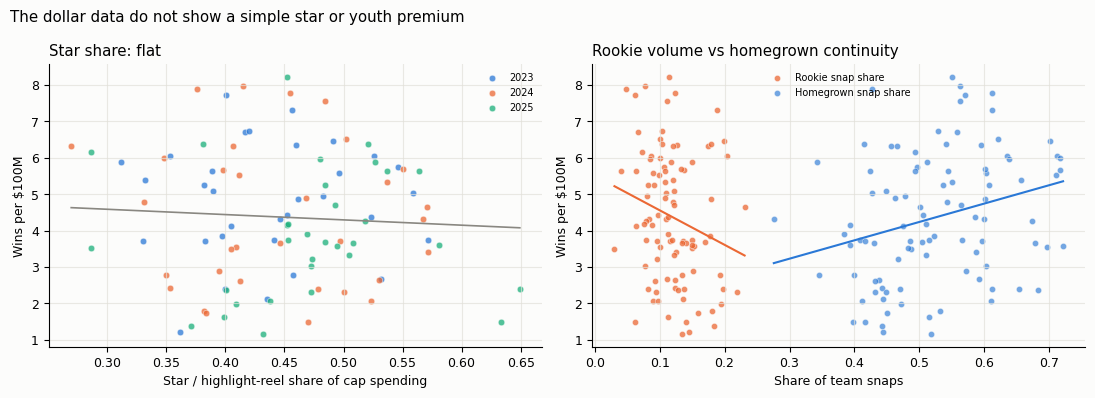

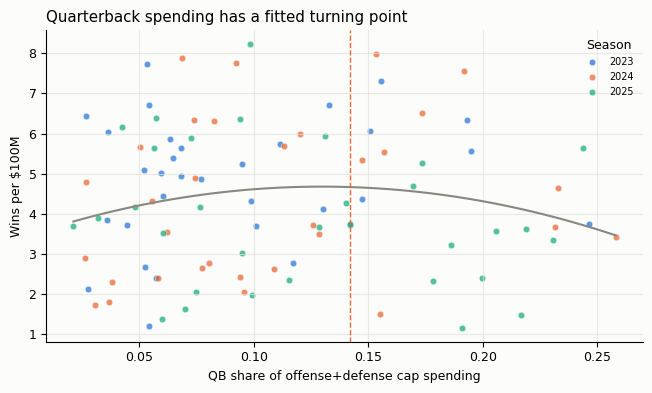

        wins  point_diff  wins_per_100m
top_qb                                 
False   8.56        1.83           3.95
True    8.31       -5.50           3.75


In [9]:

# Salary figure 1: star share is flat; rookie volume vs homegrown continuity.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for season, color in zip(sorted(panel.season.unique()), [BLUE, ORANGE, AQUA]):
    s = panel[panel.season == season]
    ax.scatter(s["star_share"], s["wins_per_100m"], s=22, c=color, alpha=.75,
               edgecolors=SURFACE, linewidths=.4, label=str(season))
coef = np.polyfit(panel["star_share"], panel["wins_per_100m"], 1)
xs = np.linspace(panel["star_share"].min(), panel["star_share"].max(), 50)
ax.plot(xs, np.polyval(coef, xs), color=GRAY, lw=1.2)
ax.set_xlabel("Star / highlight-reel share of cap spending")
ax.set_ylabel("Wins per $100M")
ax.set_title("Star share: flat", loc="left")
ax.grid(alpha=.7); ax.legend(frameon=False, fontsize=7)
ax = axes[1]
ax.scatter(panel["rookie_snap_share"], panel["wins_per_100m"], s=20, c=ORANGE,
           alpha=.75, edgecolors=SURFACE, linewidths=.4, label="Rookie snap share")
ax.scatter(panel["homegrown_snap_share"], panel["wins_per_100m"], s=20, c=BLUE,
           alpha=.65, edgecolors=SURFACE, linewidths=.4, label="Homegrown snap share")
for col, color in [("rookie_snap_share", ORANGE), ("homegrown_snap_share", BLUE)]:
    c = np.polyfit(panel[col], panel["wins_per_100m"], 1)
    xs = np.linspace(panel[col].min(), panel[col].max(), 50)
    ax.plot(xs, np.polyval(c, xs), color=color, lw=1.5)
ax.set_xlabel("Share of team snaps"); ax.set_ylabel("Wins per $100M")
ax.set_title("Rookie volume vs homegrown continuity", loc="left")
ax.grid(alpha=.7); ax.legend(frameon=False, fontsize=7)
fig.suptitle("The dollar data do not show a simple star or youth premium", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG/"salary_efficiency.png", dpi=180, bbox_inches="tight"); plt.show()

# Salary figure 2: QB share vs wins per $100M with a quadratic fit.
qdata = panel.dropna(subset=["wins", "qb_share", "log_payroll", "season_c"]).copy()
q = smf.ols("wins ~ qb_share + I(qb_share**2) + log_payroll + C(season_c)",
            data=qdata).fit(cov_type="cluster", cov_kwds={"groups": qdata["team"]})
q2 = [k for k in q.params.index if k.startswith("I(")][0]
fig, ax = plt.subplots(figsize=(6.6, 4))
for season, color in zip(sorted(panel.season.unique()), [BLUE, ORANGE, AQUA]):
    s = panel[panel.season == season]
    ax.scatter(s["qb_share"], s["wins_per_100m"], s=22, c=color, alpha=.75,
               edgecolors=SURFACE, linewidths=.4, label=str(season))
c = np.polyfit(panel["qb_share"], panel["wins_per_100m"], 2)
xs = np.linspace(panel["qb_share"].min(), panel["qb_share"].max(), 80)
ax.plot(xs, np.polyval(c, xs), color=GRAY, lw=1.5)
ax.axvline(-q.params["qb_share"]/(2*q.params[q2]), color=ORANGE, lw=1, linestyle="--")
ax.set_xlabel("QB share of offense+defense cap spending")
ax.set_ylabel("Wins per $100M")
ax.set_title("Quarterback spending has a fitted turning point", loc="left")
ax.grid(alpha=.7); ax.legend(frameon=False, fontsize=7, title="Season")
fig.tight_layout(); fig.savefig(FIG/"qb_premium.png", dpi=180, bbox_inches="tight"); plt.show()

# Top-quartile QB cap share (2025) vs the rest.
d25 = panel[panel.season == 2025].copy()
d25["top_qb"] = d25["cap_qb_share"] >= d25["cap_qb_share"].quantile(.75)
print(d25.groupby("top_qb")[["wins", "point_diff", "wins_per_100m"]].mean().round(2))


## Week-to-week check

The season-level result is robust, but it is not a single-week trigger. Using the same tracking data, next-week role is predicted by this-week role, not by this-week performance. Early-season performance also does not predict late-season role after controlling for early role. The result supports a 4–6 week rolling role review, not an automated weekly decision. The result table is embedded below; the derivation is in `src/discovery/weekly_role.py`.


In [10]:

import base64, zlib, io
WEEKLY_B64 = "eJxtks1q3EAQhO95lrHp/+655kXE4p21TeSsWS+Y5OldM2swxDkIDa2SvqpqvZyPY2/XcXlpD+dxam+jPTxv+/l93p6eH5/aa/v9432MX/ufbR+H47YfHtvlvI/tb6P7dHEWrzL1KAyIs7uWJuPS7FPDqYKBcUKaMUeVSWwhScQkNl9sWuXfSK/jcgLpDgLy4jIzN2H1xaLoVCTc8eluSyWRKaRcpGnRl8yhZ5OpyeXSC2iAq5daD/s/++d2vBxOV+iZQ6dTBCHkWkHdnUgUwwwmniNCHRyukk7JipEITuXBGhFkc0QaDEGyC4V7v7HH4TLRh+tot+NXxYaUIeRkpO6y2JzUgzuyotxpJ7SrpbCgo1JKjMqEzLmnBFf2bHzvFmyqBDOW6GLcWTQp+Y7/7H2FqgnBpip0sWAkBGc4UsNqV+/QuBnSE1zyqqPSelafbqeDZSk0TARXMJP+y/5qnDoUgd7SjKrmHtEhqhZgkT46T+yEeq/CVoCV6U4DD7GWwj/gtyYMa0YE/DmBtrQv7Ad6Ibdi"
weekly = pd.read_csv(io.StringIO(zlib.decompress(base64.b64decode(WEEKLY_B64)).decode()))
print("Weekly lead-lag (next-week role):")
print(weekly.query("model == 'weekly_lead_lag'")[["term", "coef", "ci_low", "ci_high", "p", "n"]].round(3).to_string(index=False))
print("\nEarly-season -> late-season role:")
print(weekly.query("model == 'early_late'")[["term", "coef", "ci_low", "ci_high", "p", "n"]].round(3).to_string(index=False))


Weekly lead-lag (next-week role):
   term   coef  ci_low  ci_high     p    n
 role_z  0.753   0.717    0.788 0.000 3885
 perf_z -0.006  -0.027    0.015 0.586 3885
B_draft  0.116   0.008    0.225 0.036 3885

Early-season -> late-season role:
        term  coef  ci_low  ci_high     p   n
early_role_z 0.741   0.639    0.842 0.000 282
early_perf_z 0.008  -0.072    0.087 0.846 282
     B_draft 0.093  -0.175    0.361 0.498 282


## Salary appendix: sources and limits

- **OTC positional spending** (2023–2025) is the primary star-share measure. It is cap spending by position, not a full cap ledger.
- **Archived OTC 2025 team cap pages** supply the player-level 2025 active-roster cap numbers. The 32-team snapshot matches 98% of snaps. The rent sample covers 909 players and 69% of active-cap dollars; offensive linemen and specialists are excluded because the public data have no individual performance measure.
- **nflverse** supplies snaps, rosters, stats, and schedules. Player performance is standardized within position group and season; minimums are 100 QB dropbacks, 50 RB touches, 30 WR/TE targets, and 8 games for defensive players.
- **Rent** is a positive pay-performance residual from log 2025 cap number on performance z, age, experience, and position. It is a cap-allocation residual, not a causal rent: cap hits reflect signing-bonus proration, restructures, timing, and expected future performance.
- **Soccer** uses UEFA 2025, Deloitte Money League 2025, club annual reports, and official league tables. Accounting scopes and season windows differ; the table is illustrative, not a natural experiment.

Full source notes: `docs/EXTERNAL_DATA.md` and `docs/SOCCER_DATA.md` in the repository.


## Formal appendix: what is identified

- **Combine linkage:** a 10 Hz Combine movement composite is tested against the tracking-derived performance residual. The coefficient is positive and precise; the same composite does not predict role or the role gap.
- **Role persistence:** next-season role is modeled as a function of current role, the performance residual, draft capital, position, and season, with cluster-robust standard errors. The performance coefficient is near zero; the role and draft-capital coefficients are positive. Leave-one-player-out R² and within-player changes are reported as validation.
- **What is not identified:** causal effects of coaches, teams, schemes, injuries, or contracts. Role is snaps per appearance, not full depth-chart share. The role gap is a diagnostic, not a verdict on individual players. The DB performance residual is unidentifiable (reliability 0.12) and is excluded from pooled models.
- **RJF/Xenotechnics:** the Yellow Square/Möbius lenses are treated as hypotheses. They return wide nulls; the residual finding is the allocation layer. No intent or suppression is claimed.


## Reproduce

- Data: NFL Big Data Bowl 2027, CC BY-NC 4.0. On Kaggle the notebook reads `/kaggle/input/nfl-big-data-bowl-2027/`; locally it reads `data/raw`.
- Salary panel: embedded as a compressed CSV derived from public OverTheCap positional spending (2023–2025), nflverse snaps/rosters/stats/schedules, and archived OTC 2025 team cap pages. The derivation is in `src/salary/`; sources and limits are in `docs/EXTERNAL_DATA.md`.
- Week-to-week check: embedded result table derived from the weekly tracking residuals; the derivation is in `src/discovery/weekly_role.py`.
- Main text: `writeup/submission.md`.
- Figures are written to `figures/`.
- The analysis is observational; see the limitations in the writeup.
